In [2]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
import pylab as pl
from itertools import cycle

iris = load_iris() #aqui carregamos a parte interessante da flor
#abaixo extrai os dados das dimensões - 4D
numSamples, numFeatures = iris.data.shape
print(numSamples) #amostra
print(numFeatures)#dimenssões
print(list(iris.target_names)) #nomes

150
4
[np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [3]:
X = iris.data
pca = PCA(n_components=3, whiten=True).fit(X)
X_pca = pca.transform(X)

In [4]:
print(pca.components_) #aqui é para ver que algo está acontecendo

[[ 0.36138659 -0.08452251  0.85667061  0.3582892 ]
 [ 0.65658877  0.73016143 -0.17337266 -0.07548102]
 [-0.58202985  0.59791083  0.07623608  0.54583143]]


In [5]:
print(pca.explained_variance_ratio_) #raio da variancia na flor
print(sum(pca.explained_variance_ratio_))

[0.92461872 0.05306648 0.01710261]
0.9947878161267256


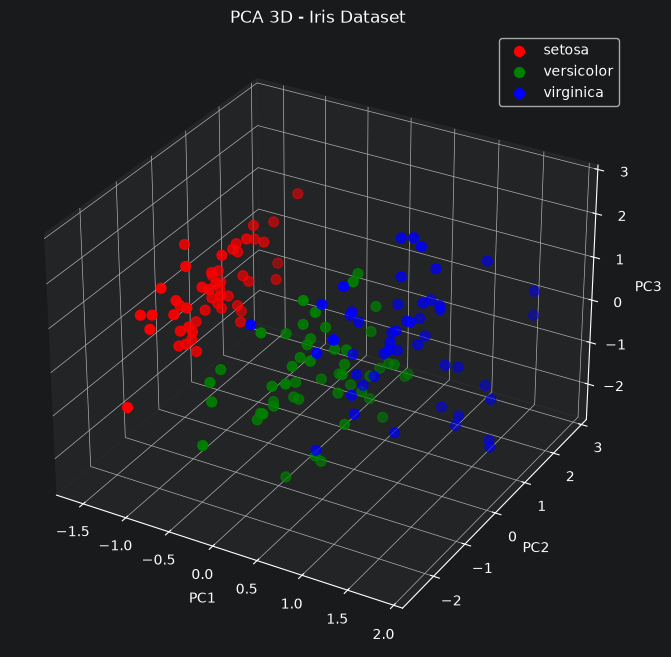

In [6]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from itertools import cycle

colors = cycle('rgb')
target_ids = range(len(iris.target_names))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

for i, c, label in zip(target_ids, colors, iris.target_names):
    ax.scatter(
        X_pca[iris.target == i, 0],  # PC1
        X_pca[iris.target == i, 1],  # PC2
        X_pca[iris.target == i, 2],  # PC3
        c=c,
        label=label,
        s=50
    )

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('PCA 3D - Iris Dataset')

ax.legend()

plt.show()

In [8]:
from sklearn.decomposition import PCA
import plotly.express as px

pca = PCA(n_components=4)
X_pca = pca.fit_transform(X)

fig = px.scatter_3d(
    x=X_pca[:,0],
    y=X_pca[:,1],
    z=X_pca[:,2],
    color=X_pca[:,3],          # 4ª dimensão não funciona de forma direta, ocorre um erro, a biblioteca nao consegue renderizar, jogo para um html abaixo
    color_continuous_scale='Viridis'
)

fig.show()


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [11]:
from sklearn.decomposition import PCA
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "browser"

# PCA com 4 componentes, esse aparece no navegador como uma visualização dinâmica
pca = PCA(n_components=4)
X_pca = pca.fit_transform(iris.data)

df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "PC3": X_pca[:, 2],
    "PC4": X_pca[:, 3],
    "Classe": [iris.target_names[i] for i in iris.target]
})

fig = px.scatter_3d(
    df,
    x="PC1",
    y="PC2",
    z="PC3",
    color="PC4",           # 4ª dimensão
    symbol="Classe",       # diferencia as espécies
    color_continuous_scale="Turbo",
    title="PCA em 4 Dimensões"
)

fig.update_traces(marker=dict(size=7))

fig.show()

In [12]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

y = iris.target

#o PCA é sensível a escala, então padronizo antes de reduzir, só agregando as informações e funcoes numa pipeline
modelo = Pipeline([
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('knn', KNeighborsClassifier(n_neighbors=5))  #K=5 vizinhos votando, como na aula do KNN
])

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

#StratifiedKFold mantém a proporção das espécies em cada fold
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

modelos = {
    '4D (sem PCA)': Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier(5))]),
    'PCA 2D': modelo,
    'PCA 1D': Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=1)), ('knn', KNeighborsClassifier(5))]),
}

#em cada rodada do K-Fold, o PCA é ajustado só nas partes de treino. A parte de teste apenas passa pelo PCA já pronto. O teste fica realmente inédito, e a nota é mais honesta.
for nome, m in modelos.items():
    scores = cross_val_score(m, X, y, cv=kfold)
    print(f"{nome}: média={scores.mean():.3f} desvio={scores.std():.3f}")

4D (sem PCA): média=0.953 desvio=0.034
PCA 2D: média=0.900 desvio=0.021
PCA 1D: média=0.913 desvio=0.027


In [14]:
from sklearn.model_selection import KFold

pipe = Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier(5))])

#o dataset da Iris vem ordenado por espécie, então sem embaralhar cada fold fica quase só com uma espécie
print(cross_val_score(pipe, X, y, cv=KFold(5, shuffle=False)).round(3))
print(cross_val_score(pipe, X, y, cv=KFold(5, shuffle=True, random_state=0)).round(3))

[1.    1.    0.8   0.933 0.733]
[1.    0.867 1.    1.    0.9  ]


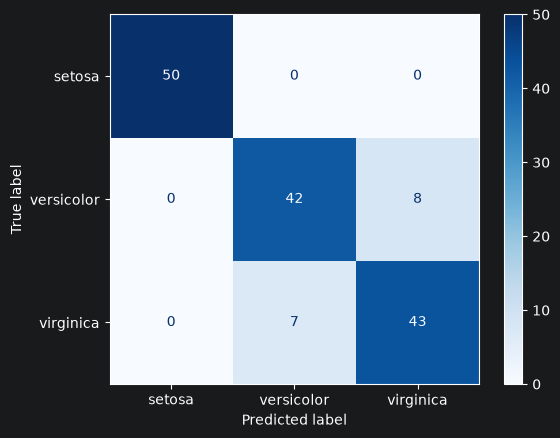

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        50
  versicolor       0.86      0.84      0.85        50
   virginica       0.84      0.86      0.85        50

    accuracy                           0.90       150
   macro avg       0.90      0.90      0.90       150
weighted avg       0.90      0.90      0.90       150



In [15]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

#cada flor é prevista por um modelo que não treinou com ela
y_pred = cross_val_predict(modelo, X, y, cv=kfold)
#a matriz de confusão pode ser feita aqui, pra cada espécie
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=iris.target_names, cmap='Blues')
plt.show()

#precision, recall e f1 de cada espécie
print(classification_report(y, y_pred, target_names=iris.target_names))

In [16]:
from sklearn.impute import SimpleImputer, KNNImputer

#apago 5% dos valores aleatoriamente pra simular dados faltantes
rng = np.random.default_rng(0)
X_sujo = X.copy()
mascara = rng.random(X_sujo.shape) < 0.05
X_sujo[mascara] = np.nan
print(mascara.sum(), "valores apagados")

imputadores = {
    'média': SimpleImputer(strategy='mean'),
    'mediana': SimpleImputer(strategy='median'),
    'KNN': KNNImputer(n_neighbors=5)  #preenche olhando os vizinhos mais parecidos
}

for nome, imp in imputadores.items():
    pipe = Pipeline([('imp', imp), ('scale', StandardScaler()),
                     ('pca', PCA(n_components=2)), ('knn', KNeighborsClassifier(5))])
    print(nome, round(cross_val_score(pipe, X_sujo, y, cv=kfold).mean(), 3))

23 valores apagados
média 0.9
mediana 0.893
KNN 0.893
